# 02 - EDA et Visualisation

Objectif : explorer le dataset visuellement.
- Distribution des classes (equilibre ?)
- Exemples d'images par classe


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_preprocessing import chargement_pretraitement_dataset

DATA_PATH = PROJECT_ROOT / "data" / "raw"
X, y = chargement_pretraitement_dataset(str(DATA_PATH))
print(f"{X.shape[0]} images - classes : {set(y)}")

2026-10-17 01:28:29.043706: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-17 01:28:29.104530: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-17 01:28:31.113187: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-17 01:28:37.999535: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off,

Classes detectees : ['.gitkeep', 'glioma', 'meningioma', 'notumor', 'pituitary']
 -> Classe : glioma
 -> Classe : meningioma
 -> Classe : notumor
 -> Classe : pituitary

Chargement termine : 7023 images | {np.str_('glioma'), np.str_('notumor'), np.str_('meningioma'), np.str_('pituitary')}
7023 images - classes : {np.str_('glioma'), np.str_('notumor'), np.str_('meningioma'), np.str_('pituitary')}


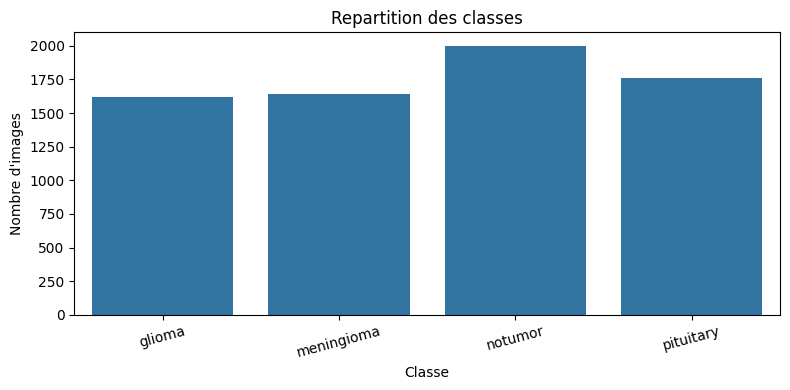

In [2]:
# 1. Distribution des classes
plt.figure(figsize=(8, 4))
sns.countplot(x=y)
plt.title("Repartition des classes")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

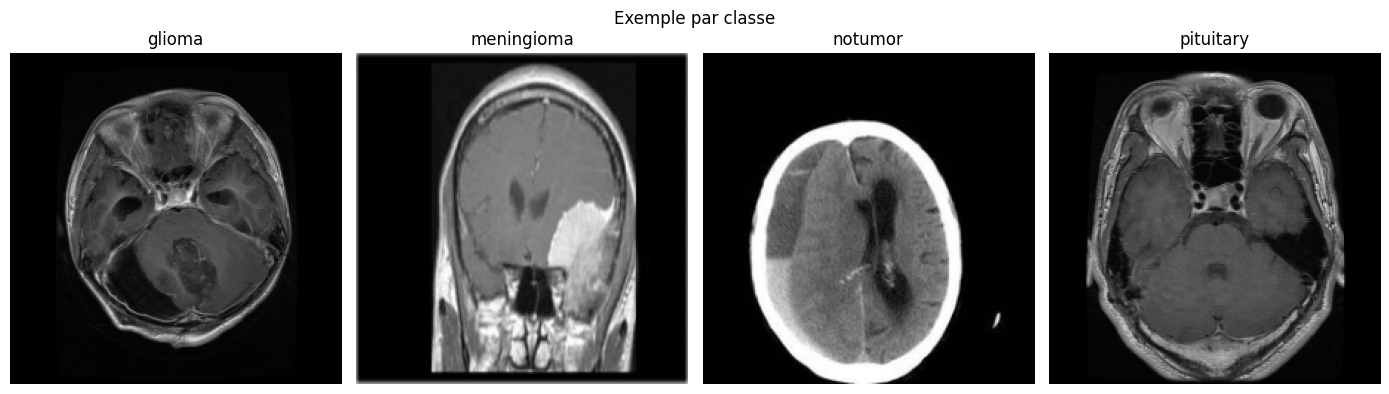

In [3]:
# 2. Exemples d'images (1 par classe)
classes = sorted(set(y))
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for i, cls in enumerate(classes):
    idx = np.where(y == cls)[0][0]
    axes[i].imshow(X[idx])
    axes[i].set_title(cls)
    axes[i].axis("off")
plt.suptitle("Exemple par classe")
plt.tight_layout()
plt.show()

### Questions a se poser
- Une classe a-t-elle beaucoup moins d'images ? -> on utilise `class_weights`
- Les images sont-elles de bonne qualite ?